In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

clean_df = pd.read_csv(
     r"C:\Users\ASUS\OneDrive\Desktop\ecommerce-delivery-operations-analysis/data/cleaned/supply_chain_cleaned.csv",
    parse_dates=[
        "order date (DateOrders)",
        "shipping date (DateOrders)"
    ]
)

print("Dataset shape:", clean_df.shape)

Dataset shape: (180519, 43)


In [40]:
# Which markets generate the most sales and profit?


regional_analysis = (
    clean_df.groupby("Market")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Unique_Orders=("Order Id", "nunique"),
        Average_Profit=("Order Profit Per Order", "mean")
    )
    .reset_index()
    .sort_values("Total_Profit", ascending=False)
)

regional_analysis


,Market,Total_Sales,Total_Profit,Unique_Orders,Average_Profit
1,Europe,1.087240e+07,1.169443e+06,18561,23.271571
2,LATAM,1.027761e+07,1.123322e+06,17181,21.772330
3,Pacific Asia,8.273744e+06,8.577534e+05,17577,20.788983
4,USCA,5.066529e+06,5.643138e+05,8579,21.873475
0,Africa,2.294453e+06,2.520712e+05,3854,21.704080


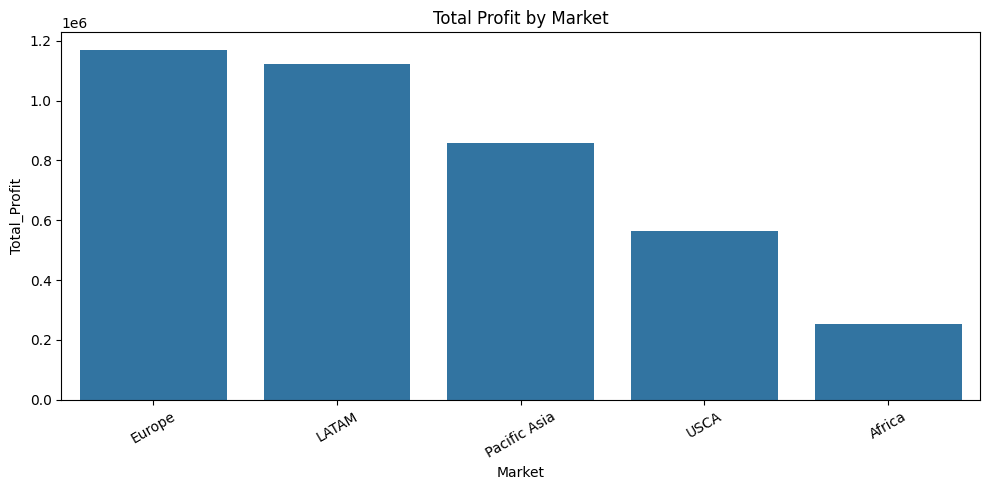

In [41]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=regional_analysis,
    x="Market",
    y="Total_Profit"
)

plt.title("Total Profit by Market")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [42]:
# Which customer segments contribute the most profit?


segment_analysis = (
    clean_df.groupby("Customer Segment")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Unique_Orders=("Order Id", "nunique")
    )
    .reset_index()
    .sort_values("Total_Profit", ascending=False)
)

segment_analysis

,Customer Segment,Total_Sales,Total_Profit,Unique_Orders
0,Consumer,1.909579e+07,2.073488e+06,34119
1,Corporate,1.116841e+07,1.202575e+06,19856
2,Home Office,6.520538e+06,6.908403e+05,11777


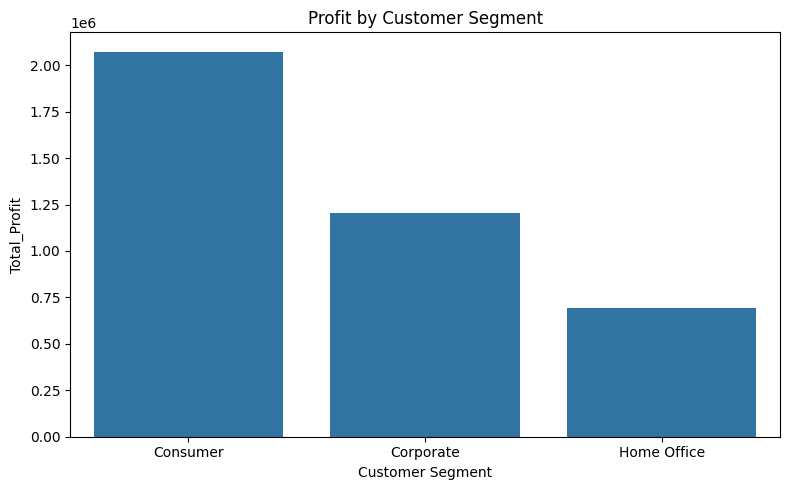

In [43]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=segment_analysis,
    x="Customer Segment",
    y="Total_Profit"
)

plt.title("Profit by Customer Segment")
plt.tight_layout()
plt.show()

In [44]:
# Which products have the greatest total losses?

product_analysis = (
    clean_df.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Order Profit Per Order", "sum"),
        Average_Profit=("Order Profit Per Order", "mean"),
        Record_Count=("Order Id", "count")
    )
    .reset_index()
)

loss_making_products = (
    product_analysis[
        product_analysis["Total_Profit"] < 0
    ]
    .sort_values("Total_Profit")
)

loss_making_products.head(10)



,Product Name,Total_Sales,Total_Profit,Average_Profit,Record_Count
77,SOLE E35 Elliptical,29999.849850,-965.119968,-64.341331,15
9,Bushnell Pro X7 Jolt Slope Rangefinder,6599.889892,-255.950003,-23.268182,11
76,SOLE E25 Elliptical,9999.899902,-169.559997,-16.956000,10


In [45]:
# How often does actual shipping take longer than scheduled?


clean_df["Shipping_Delay_Days"] = (
    clean_df["Days for shipping (real)"]
    - clean_df["Days for shipment (scheduled)"]
)

print(
    "Records exceeding scheduled shipping days:",
    (clean_df["Shipping_Delay_Days"] > 0).sum()
)

print(
    "Average shipping delay (days):",
    clean_df["Shipping_Delay_Days"].mean().round(2)
)

Records exceeding scheduled shipping days: 103400
Average shipping delay (days): 0.57


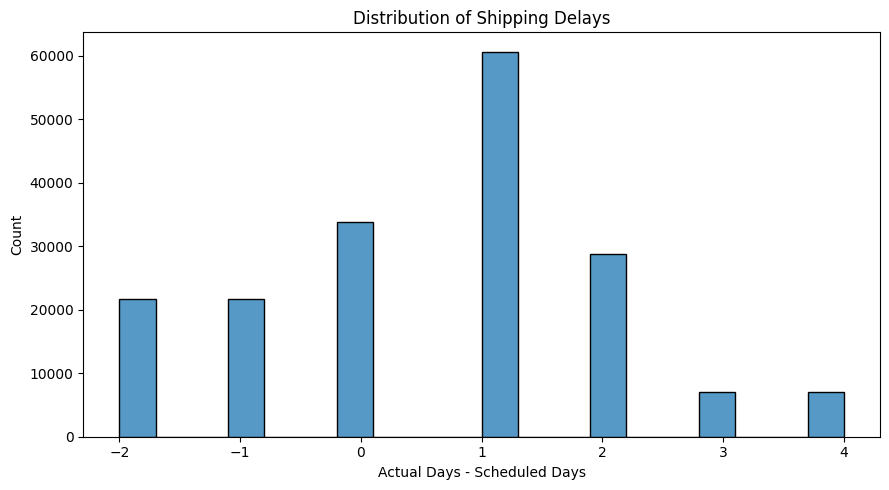

In [46]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=clean_df,
    x="Shipping_Delay_Days",
    bins=20
)

plt.title("Distribution of Shipping Delays")
plt.xlabel("Actual Days - Scheduled Days")
plt.tight_layout()
plt.show()

In [47]:
print("Cleaned CSV rows:", len(clean_df))

clean_df.to_csv(
    r"C:\Users\ASUS\OneDrive\Desktop\ecommerce-delivery-operations-analysis/data/cleaned/supply_chain_cleaned.csv",
    index=False
)

Cleaned CSV rows: 180519


In [48]:
import os

csv_path = (
    r"C:\Users\ASUS\OneDrive\Desktop"
    r"\ecommerce-delivery-operations-analysis"
    r"\data\cleaned\supply_chain_cleaned.csv"
)

print("File exists:", os.path.exists(csv_path))

check_df = pd.read_csv(csv_path, encoding="utf-8")

print("Rows:", len(check_df))
print("Columns:", len(check_df.columns))

File exists: True
Rows: 180519
Columns: 43


In [49]:
%pip install sqlalchemy pymysql

Note: you may need to restart the kernel to use updated packages.


In [50]:
from sqlalchemy import create_engine, URL
from getpass import getpass

mysql_user = input("MySQL username: ")
mysql_password = getpass("MySQL password: ")

connection_url = URL.create(
    drivername="mysql+pymysql",
    username=mysql_user,
    password=mysql_password,
    host="localhost",
    port=3306,
    database="supply_chain_analysis",
    query={"charset": "utf8mb4"}
)

engine = create_engine(connection_url)

with engine.connect() as connection:
    print("MySQL connection successful!")

MySQL connection successful!


In [51]:
import pandas as pd

csv_path = (
    r"C:\Users\ASUS\OneDrive\Desktop"
    r"\ecommerce-delivery-operations-analysis"
    r"\data\cleaned\supply_chain_cleaned.csv"
)

clean_df = pd.read_csv(csv_path, encoding="utf-8")

print("Rows to import:", len(clean_df))

clean_df.to_sql(
    name="supply_chain_python_import",
    con=engine,
    if_exists="fail",
    index=False,
    chunksize=1000
)

print("Import completed!")

Rows to import: 180519
Import completed!
